# Chennai Tmax: EDA and Extreme Value Analysis (Person B, Part 1)
Source: OpenCity daily temperature, 1951 to 2024-06-22. **Caveat:** IMD gridded data up to 2020, Nungambakkam station from 2021, so there is a splice at 2021 that can bias trend results.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from src import evt_analysis as evt
plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3})
s = evt.load_raw_tmax('../data/raw/chennai_daily_temp.csv')
print(s.index.min().date(), s.index.max().date(), len(s), 'rows;', s.isna().sum(), 'missing Tmax')

1951-01-01 2024-06-22 26837 rows; 10 missing Tmax


## 1. Data quality

In [2]:
raw = pd.read_csv('../data/raw/chennai_daily_temp.csv')
print('Non-numeric Tmax entries ("-----"):', (raw['Temp Max']=='-----').sum())
print('Missing by year (top):'); print(s.isna().groupby(s.index.year).sum().loc[lambda x:x>0])
print('Rain column is empty before 2021 (', raw['Rain'].isna().sum(), 'of', len(raw), 'rows): do not use rain as a feature for the full history.')
print(s.describe().round(2))

Non-numeric Tmax entries ("-----"): 9
Missing by year (top):
Date
2019    1
2021    2
2022    5
2023    1
2024    1
Name: tmax, dtype: int64
Rain column is empty before 2021 ( 25568 of 26837 rows): do not use rain as a feature for the full history.
count    26827.00
mean        33.68
std          3.37
min         23.55
25%         30.88
50%         33.87
75%         36.15
max         44.96
Name: tmax, dtype: float64


## 2. Seasonality and long-term change

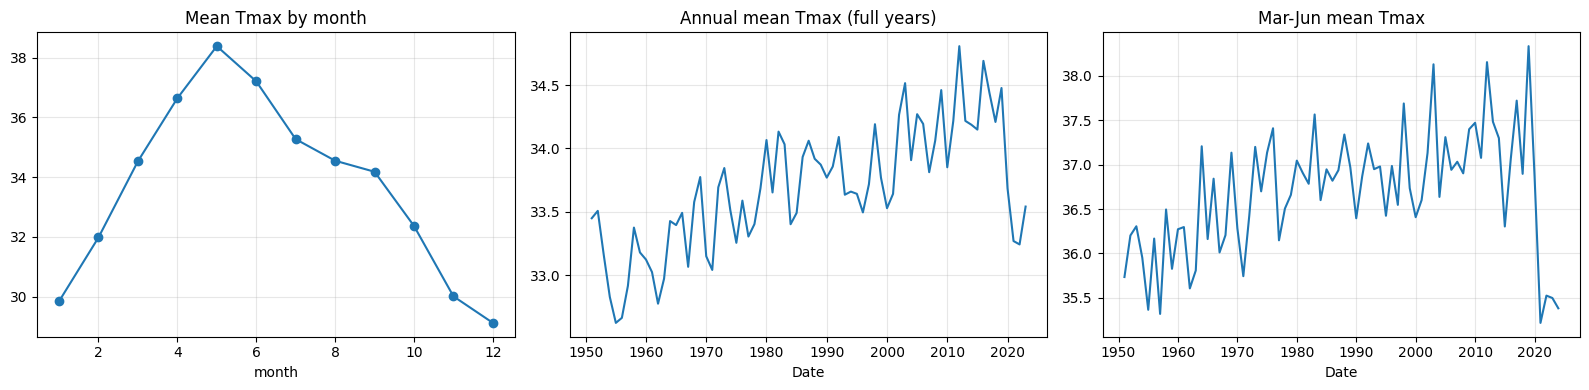

In [3]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
s.groupby(s.index.month).mean().plot(ax=ax[0],marker='o'); ax[0].set_title('Mean Tmax by month'); ax[0].set_xlabel('month')
ann=s.groupby(s.index.year).mean(); ann[s.groupby(s.index.year).count()>300].plot(ax=ax[1]); ax[1].set_title('Annual mean Tmax (full years)')
smr=evt.summer_only(s); smr.groupby(smr.index.year).mean().plot(ax=ax[2]); ax[2].set_title('Mar-Jun mean Tmax')
plt.tight_layout(); plt.show()

## 3. Hot-day frequency (model-free)

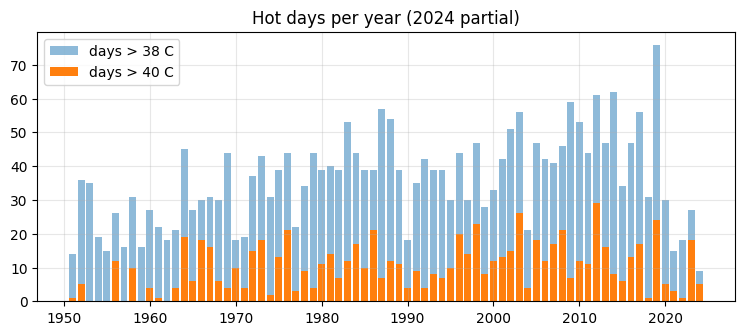

Date
1950     3.1
1960     7.8
1970     9.9
1980    12.2
1990    10.7
2000    14.5
2010    13.7
2020     6.4
Name: mean days>40C per year, dtype: float64


In [4]:
d40=evt.empirical_exceedance_by_year(s,40); d38=evt.empirical_exceedance_by_year(s,38)
fig,ax=plt.subplots(figsize=(9,3.5)); ax.bar(d38.index,d38.values,label='days > 38 C',alpha=.5); ax.bar(d40.index,d40.values,label='days > 40 C'); ax.legend(); ax.set_title('Hot days per year (2024 partial)'); plt.show()
print(d40.groupby(lambda y:y//10*10).mean().round(1).rename('mean days>40C per year'))

## 4. Block maxima and GEV\nAnnual maximum of Mar-Jun Tmax. Years with fewer than 60 summer observations are dropped.

n=74  xi=-0.224  loc=41.17  scale=1.12  KS p=0.30
xi < 0 means a bounded upper tail: plausible for Tmax, but with 74 points xi is uncertain.


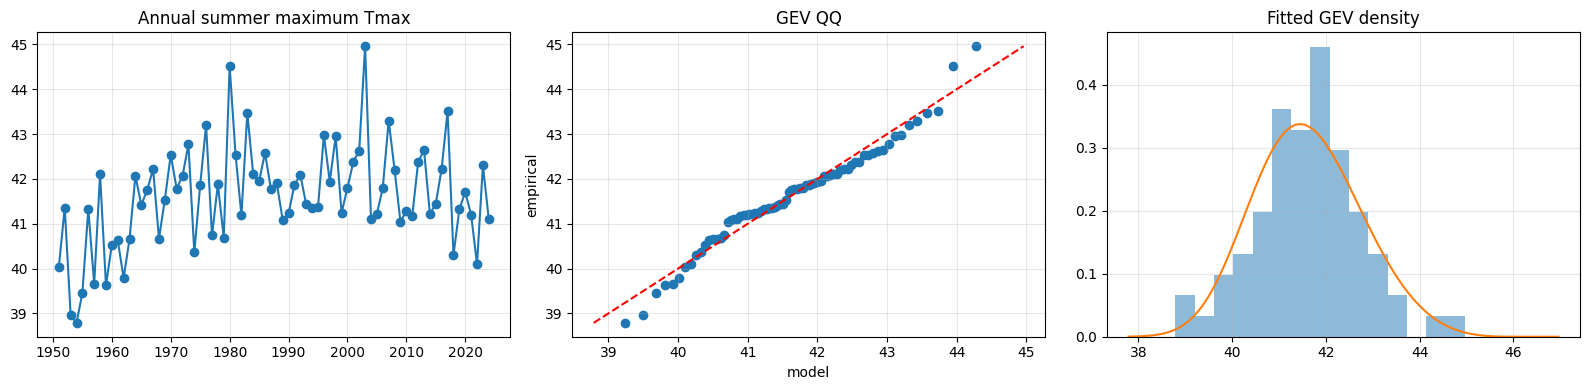

In [5]:
bm=evt.block_maxima(s); gev=evt.fit_gev(bm)
print(f'n={gev.n}  xi={gev.xi:.3f}  loc={gev.loc:.2f}  scale={gev.scale:.2f}  KS p={evt.gev_ks_pvalue(bm,gev):.2f}')
print('xi < 0 means a bounded upper tail: plausible for Tmax, but with 74 points xi is uncertain.')
fig,ax=plt.subplots(1,3,figsize=(16,4))
ax[0].plot(bm.index,bm.values,'o-'); ax[0].set_title('Annual summer maximum Tmax')
q=evt.gev_qq(bm,gev); ax[1].scatter(q.model,q.empirical); lim=[q.min().min(),q.max().max()]; ax[1].plot(lim,lim,'r--'); ax[1].set_title('GEV QQ'); ax[1].set_xlabel('model'); ax[1].set_ylabel('empirical')
ax[2].hist(bm,bins=15,density=True,alpha=.5); xs=np.linspace(bm.min()-1,bm.max()+2,200); ax[2].plot(xs,stats.genextreme.pdf(xs,-gev.xi,gev.loc,gev.scale)); ax[2].set_title('Fitted GEV density')
plt.tight_layout(); plt.show()

## 5. Return levels with 95% CIs

,T,estimate,lo95,hi95
0,2.0,41.57,41.30,41.88
1,5.0,42.60,42.25,42.89
2,10.0,43.16,42.76,43.47
3,25.0,43.74,43.17,44.11
4,50.0,44.09,43.39,44.58
5,100.0,44.40,43.56,45.06


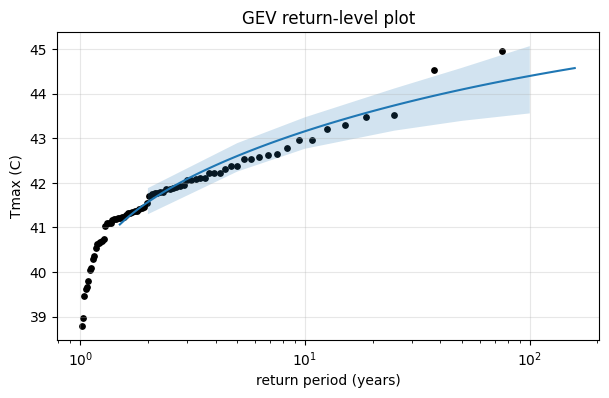

P(annual summer max > 42 C): 0.36  > 44 C: 0.0242


In [6]:
rl=evt.bootstrap_gev_return_levels(bm,T=[2,5,10,25,50,100],n_boot=500); display(rl.round(2))
T=np.logspace(np.log10(1.5),2.2,100); n=len(bm); emp_T=(n+1)/np.arange(1,n+1); emp=np.sort(bm.values)[::-1]
fig,ax=plt.subplots(figsize=(7,4)); ax.semilogx(T,gev.return_level(T)); ax.scatter(emp_T,emp,s=15,c='k'); ax.fill_between(rl['T'],rl.lo95,rl.hi95,alpha=.2)
ax.set_xlabel('return period (years)'); ax.set_ylabel('Tmax (C)'); ax.set_title('GEV return-level plot'); plt.show()
print('P(annual summer max > 42 C):', round(evt.gev_exceedance_prob(gev,42),3), ' > 44 C:', round(evt.gev_exceedance_prob(gev,44),4))

## 6. Stationarity check\nA trend or the 2021 splice would violate the stationary-GEV assumption.

In [7]:
print(evt.trend_test(bm)); display(evt.compare_periods(bm,1991).round(2))
print('Annual-max series after the splice (2021+):'); print(bm.loc[2019:].round(1).to_dict())

{'tau': 0.18717580140512158, 'p_value': 0.018430404830576206, 'slope_per_decade': 0.14516030645161265}


,period,n,xi,loc,scale,RL10,RL50
0,early,40,-0.25,40.93,1.21,43.01,43.93
1,late,34,-0.07,41.47,0.79,43.12,44.18


Annual-max series after the splice (2021+):
{2019: 41.3, 2020: 41.7, 2021: 41.2, 2022: 40.1, 2023: 42.3, 2024: 41.1}


## 7. Peaks over threshold (cross-check)

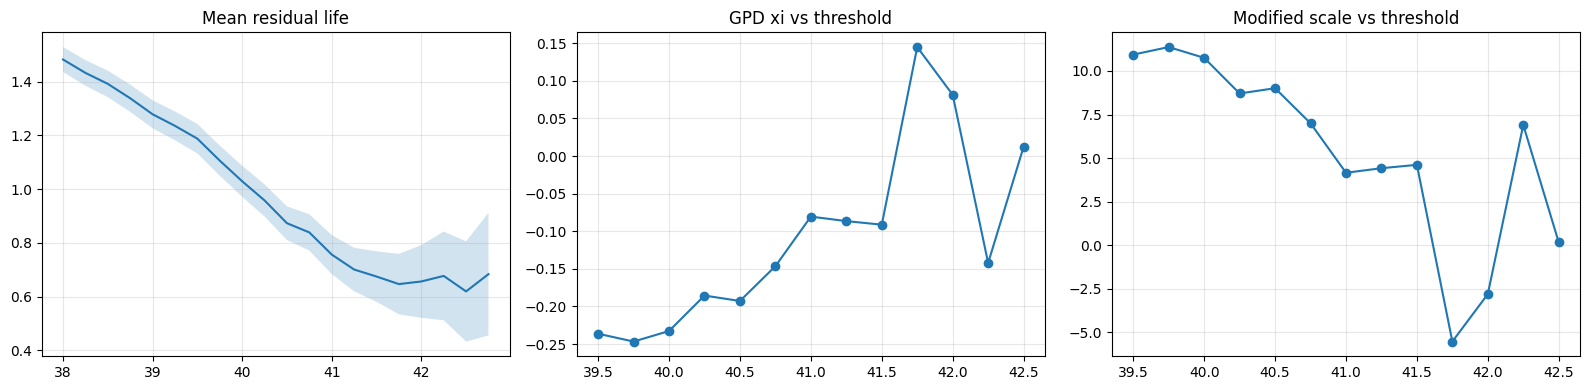

In [8]:
summ=evt.summer_only(s).dropna(); us=np.arange(38,43,.25)
mrl=evt.mean_residual_life(summ,us); ts=evt.threshold_stability(s,np.arange(39.5,42.6,.25))
fig,ax=plt.subplots(1,3,figsize=(16,4))
ax[0].plot(mrl.u,mrl.mean_excess); ax[0].fill_between(mrl.u,mrl.lo,mrl.hi,alpha=.2); ax[0].set_title('Mean residual life')
ax[1].plot(ts.u,ts.xi,'o-'); ax[1].set_title('GPD xi vs threshold'); ax[2].plot(ts.u,ts.mod_scale,'o-'); ax[2].set_title('Modified scale vs threshold')
plt.tight_layout(); plt.show()

In [9]:
u=float(np.percentile(summ,97)); gpd=evt.fit_gpd(s,u)
print(f'threshold={u:.2f} C (97th pct of summer days)  cluster peaks={gpd.n_peaks}  xi={gpd.xi:.3f}  sigma={gpd.sigma:.2f}')
cmp=pd.DataFrame({'T':[10,25,50,100],'GEV':gev.return_level([10,25,50,100]),'GPD':gpd.return_level([10,25,50,100])}); display(cmp.round(2))

threshold=41.19 C (97th pct of summer days)  cluster peaks=80  xi=-0.045  sigma=0.79


,T,GEV,GPD
0,10,43.16,42.97
1,25,43.74,43.61
2,50,44.09,44.07
3,100,44.40,44.52


## 8. Findings to hand over\n- Both methods put the 50-year return level near 44 C. The 100-year level is an extrapolation with a wide CI: report it as such.\n- Annual maxima show a weak upward trend; the early vs late GEV comparison shows little change in the top return levels, so the stationary model is acceptable for this project, with the caveat noted.\n- Heatwave days per year (>40 C) rose from the 1950s to the 2000s but are lower in the 2020s sample, which coincides with the station splice and should not be read as a real cooling.\n- For Persons A and C: Tmax-only EVT cannot flag IMD heatwaves exactly (IMD uses departure from normal, or an absolute 40 C threshold for plains); the label rules in `heatwave_labels.py` should be the source of truth.